# Рынок новых автомобилей Казахстана в 2019 году: очистка данных и позиция «Меркур Авто»

**Бизнес-контекст.** Автодилерский холдинг анализирует продажи новых
автомобилей в Казахстане за девять месяцев 2019 года. Один из автоцентров
холдинга — «Меркур Авто» (Mercur Auto) — хочет понять своё положение на рынке
и найти точки роста.

**Проблема данных.** Выгрузка пришла в «операционном» виде: десятичная
запятая, 80+ вариантов записи коробки передач, одни и те же привод, страна и
компания записаны по-разному, в объёме двигателя встречаются мощность и
ошибки автозаполнения, часть значений сдвинута на соседний столбец. Без
очистки любые доли и средние будут искажены.

**Цели.**

1. *Техническая* — привести датасет к виду, пригодному для анализа и загрузки
   в BI, и автоматизировать очистку скриптом для похожих выгрузок
   (`src/kz_auto_market/cleaning.py`, команда `kz-auto-clean`).
2. *Аналитическая* — провести разведочный анализ всего рынка и оценить долю,
   структуру продаж и ключевые показатели «Меркур Авто» в сравнении с рынком,
   определить сильные и слабые стороны и предложить решения.

Каждый шаг очистки ниже выполняется функцией из `cleaning.py` — тем же кодом,
что и в скрипте; в конце раздела 2 результат сверяется с сохранённым
`data/processed/autokz2019_clean.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from kz_auto_market import cleaning, market

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_PATH = ROOT / cleaning.RAW_PATH
CLEAN_PATH = ROOT / cleaning.CLEAN_PATH
MERCUR = cleaning.FOCUS_COMPANY
PREMIUM_BRANDS = [
    'Audi',
    'BMW',
    'Cadillac',
    'Infiniti',
    'Jaguar',
    'Land Rover',
    'Lexus',
    'Mercedes-Benz',
    'Mini',
    'Porsche',
    'Volvo',
]
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
plt.rcParams['figure.dpi'] = 90

## 1. Загрузка и первичный осмотр данных

In [2]:
# Разделитель — точка с запятой, десятичный знак — запятая: без decimal=','
# цены и количество прочитались бы строками
raw = cleaning.read_raw(RAW_PATH)
print(f'Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}')
raw.dtypes.value_counts()

Строк: 39966, столбцов: 25


str        21
float64     3
int64       1
Name: count, dtype: int64

In [3]:
raw.head(3).T

,0,1,2
Год,2019,2019,2019
Месяц,Май,Август,Апрель
Компания,Mercur Auto,Mercur Auto,Mercur Auto
Бренд,Audi,Audi,Audi
Модель,A3,A3,A4
Модификация,TFSI,TFSI,TFSI
Год выпуска,2018,2018,2018
Страна-производитель,Германия,Германия,Германия
Вид топлива,Бензин,Бензин,Бензин
"Объём двиг, л,","1,4","1,4","1,4"


In [4]:
missing = pd.DataFrame(
    {
        'пропусков': raw.isna().sum(),
        'доля, %': (raw.isna().mean() * 100).round(1),
        'уникальных': raw.nunique(),
    }
)
missing.sort_values('пропусков', ascending=False)

,пропусков,"доля, %",уникальных
Форма расчета,25928,64.9,21
Тип клиента,7047,17.6,9
Сегмент,6761,16.9,119
Тип привода,4289,10.7,26
"Объём двиг, л,",4258,10.7,114
Модификация,3591,9.0,1383
Коробка передач,3255,8.1,83
Вид топлива,3140,7.9,10
Год выпуска,501,1.3,9
Количество,6,0.0,56


Столбцы из плана работы удаляются: они дублируют другие признаки, не нужны
для анализа рынка или содержат критичное число пропусков. В выгрузке у
некоторых из них другие названия:

| В плане | В выгрузке | Причина |
|---------|------------|---------|
| Дилер | Наименование дилерского центра | повторяет «Компания» + «Регион» |
| Тип платежа | Форма расчета | 65% пропусков, 21 вариант записи |
| Сегмент | Сегмент | 17% пропусков и 119 вариантов; сегментацию дают «Сегментация 2013» и «Класс 2013» |
| Сегмент ЕПР | Сегментация Eng | буквенные коды тех же классов, что «Класс 2013» |
| Локализация | Локализация производства | однозначно следует из страны производства |
| Тип клиента | Тип клиента | 18% пропусков |
| Модификация | Модификация | свободный текст комплектации |

Названия «Стоимость», «Итоговая стоимость» и «Сегмент 2013» из плана
соответствуют столбцам «Цена, USD», «Продажа, USD» и «Сегментация 2013».

In [5]:
data = cleaning.rename_columns(cleaning.drop_unused_columns(raw))
print(list(data.columns))

['year', 'month', 'company', 'brand', 'model', 'release_year', 'country', 'fuel', 'engine_volume', 'transmission', 'drive', 'region', 'quantity', 'price_usd', 'sale_usd', 'province', 'segment_2013', 'class_2013']


In [6]:
def volume(df):
    """Строки, проданные автомобили и выручка таблицы."""
    return pd.Series(
        {
            'строк': len(df),
            'автомобилей': df['quantity'].sum(),
            'выручка, млн USD': round(df['sale_usd'].sum() / 1e6, 1),
        }
    )


print(f'Полностью пустых строк: {data.isna().all(axis=1).sum()}')
print(f'Явных дубликатов: {data.duplicated().sum()}')
before_dedup = data
data = cleaning.drop_empty_and_duplicates(data)
pd.DataFrame({'до': volume(before_dedup), 'после': volume(data)})

Полностью пустых строк: 0
Явных дубликатов: 23471


,до,после
строк,39966.0,16495.0
автомобилей,53874.0,30335.0
"выручка, млн USD",1349.2,677.6


Пустых строк нет, явных дубликатов — 23 471, больше половины строк. Они
удалены по плану работы. Важное ограничение: в выгрузке нет VIN или номера
сделки, поэтому две одинаковые строки могут быть двумя проданными
автомобилями одной модели в одном месяце. Удаление дубликатов уменьшает
абсолютные объёмы рынка (с 53.9 до 30.3 тыс. автомобилей), поэтому ниже
выводы строятся на долях и средних, а в разделе 4 проверено, что доля
«Меркур Авто» от удаления дубликатов почти не меняется.

**Решение для источника данных:** добавить в выгрузку идентификатор сделки
или VIN — тогда настоящие дубли можно будет отличить от повторных продаж.

## 2. Глубокая очистка и преобразование данных

### 2.1 Сдвинутые значения

В части строк Renault и UAZ объём двигателя записан в «Вид топлива», коробка
передач — в «Объём двигателя», а привод — в «Коробку передач». Признак
такой строки — число в столбце топлива.

In [7]:
shifted = data['fuel'].str.fullmatch(r'\d+(,\d+)?', na=False)
columns = ['brand', 'model', 'fuel', 'engine_volume', 'transmission', 'drive']
display(data.loc[shifted, columns].drop_duplicates())
data = cleaning.fix_shifted_columns(data)
data.loc[shifted, columns].drop_duplicates()

,brand,model,fuel,engine_volume,transmission,drive
11187,Renault,Duster,2,MT,4WD,4WD
11188,Renault,Duster,2,AT,4WD,4WD
11191,Renault,Duster,"1,6",MT,4WD,4WD
11193,Renault,Duster,"1,6",AT,Передний,Передний
11560,Renault,Sandero,"1,6",0,0,0
11561,Renault,Sandero,"1,6",MT,Передний,Передний
14810,UAZ,3741,0,"2,693",5 МТ,Полный


,brand,model,fuel,engine_volume,transmission,drive
11187,Renault,Duster,NaN,2,MT,4WD
11188,Renault,Duster,NaN,2,AT,4WD
11191,Renault,Duster,NaN,"1,6",MT,4WD
11193,Renault,Duster,NaN,"1,6",AT,Передний
11560,Renault,Sandero,NaN,"1,6",0,0
11561,Renault,Sandero,NaN,"1,6",MT,Передний
14810,UAZ,3741,0,"2,693",5 МТ,Полный


### 2.2 Страна производства — коды ALPHA-3

In [8]:
countries_before = data['country']
data = cleaning.encode_countries(data)
print(f'Без кода: {data["country"].isna().sum()}')
pd.crosstab(countries_before, data['country']).idxmax(axis=1).to_frame('код')

Без кода: 0


,код
country,
UK,GBR
Австрия,AUT
Белоруссия,BLR
Бельгия,BEL
Венгрия,HUN
Германия,DEU
Испания,ESP
Китай,CHN
Корея,KOR


### 2.3 Вид топлива — F, D, E, HYB

Регистр и пробелы в «бензин » и «дизель » убираются, «Электричество» и
«Электро» объединяются. Значения «0» и сдвинутые числа становятся пропуском;
Jaguar I-Pace размечен как электромобиль по описанию модели.

In [9]:
fuel_before = data['fuel'].fillna('пропуск')
data = cleaning.encode_fuels(data)
pd.crosstab(fuel_before, data['fuel'].fillna('пропуск'))

fuel,D,E,F,HYB,пропуск
fuel,,,,,
0,0,0,0,0,3
Бензин,0,0,14699,0,0
Дизель,602,0,0,0,0
Электричество,0,1,0,0,0
Электро,0,3,0,0,0
бензин,0,0,53,0,0
гибрид,0,0,0,8,0
дизель,9,0,0,0,0
пропуск,0,1,0,0,1116


### 2.4 Тип привода — 4WD, FWD, RWD

26 вариантов записи сводятся к трём: «4WD», «Полный», «AWD», «quattro»,
«4Motion», «4х4» — `4WD`; «Передний», «FF», «FWD» — `FWD`; «Задний», «RWD»,
«4х2» — `RWD`. Обозначение «2WD» без уточнения у грузовиков, автобусов,
пикапов и Hyundai H-1 означает задний привод, у легковых и кроссоверов —
передний. «0», «#Н/Д» и «Астана» (ошибка ввода) — пропуск.

In [10]:
drive_before = data['drive'].fillna('пропуск')
data = cleaning.unify_drives(data)
pd.crosstab(drive_before, data['drive'].fillna('пропуск'))

drive,4WD,FWD,RWD,пропуск
drive,,,,
#Н/Д,0,0,0,3
0,0,0,0,31
2 WD,0,1675,14,0
2WD,0,1153,143,0
4 WD,887,0,0,0
4Motion,25,0,0,0
4WD,3852,0,0,0
4X2,0,0,2,0
4X4,2,0,0,0


### 2.5 Коробка передач — «Автомат» и «Механика»

Признаки автомата: AT, CVT, AMT, DSG, DCT, PDK, Tiptronic, Steptronic,
G-Tronic, редуктор электромобиля; механики — MT, М/T, МКПП, «Мех.».
Кириллические «А», «Т», «М» в записях вида «6 АТ» заменяются латинскими.

In [11]:
transmission_before = data['transmission']
print(f'Вариантов записи: {transmission_before.nunique()}')
data = cleaning.simplify_transmissions(data)
mapping = (
    pd.DataFrame({'было': transmission_before, 'стало': data['transmission']})
    .value_counts(dropna=False)
    .reset_index(name='строк')
)
display(mapping.head(12))
data['transmission'].value_counts(dropna=False)

Вариантов записи: 81


,было,стало,строк
0,AT,Автомат,2962
1,6 AT,Автомат,2938
2,Мех.,Механика,1274
3,MT,Механика,1230
4,CVT,Автомат,1114
5,NaN,NaN,1048
6,5МТ,Механика,992
7,5 МТ,Механика,616
8,CVT (вариатор),Автомат,524
9,6AT,Автомат,512


transmission
Автомат     10718
Механика     4722
NaN          1055
Name: count, dtype: int64

### 2.6 Пропуски технических признаков

Пропуск заполняется значением модели, только если у модели оно одно:
например, у всех продаж модели только механика. Если вариантов несколько,
пропуск остаётся — угадывать нельзя.

In [12]:
technical = ['fuel', 'transmission', 'drive']
missing_before = data[technical].isna().sum()
data = cleaning.fill_from_model(data, technical)
pd.DataFrame({'до': missing_before, 'после': data[technical].isna().sum()})

,до,после
fuel,1119,614
transmission,1055,820
drive,1404,1076


### 2.7 Числовые столбцы и аномалии продаж

In [13]:
print(data[['quantity', 'price_usd', 'sale_usd']].dtypes.to_dict())
print(f'Строк без количества: {data["quantity"].isna().sum()}')
data = cleaning.convert_numbers(data)
difference = (data['sale_usd'] - data['price_usd'] * data['quantity']).abs()
print(f'Наибольшее расхождение продажи и цены × количество: {difference.max():.2f} USD')
sale_columns = ['company', 'brand', 'model', 'quantity', 'sale_usd']
display(data.loc[data['is_return'], sale_columns])
data.loc[
    data['is_wholesale'], ['company', 'brand', 'model', 'region', 'quantity']
].sort_values('quantity', ascending=False)

{'quantity': dtype('float64'), 'price_usd': dtype('float64'), 'sale_usd': dtype('float64')}
Строк без количества: 6
Наибольшее расхождение продажи и цены × количество: 0.25 USD


,company,brand,model,quantity,sale_usd
11984,БИПЭК АВТО,Skoda,Superb,-1,-35588.25


,company,brand,model,region,quantity
6841,БИПЭК АВТО,Lada,4x4,Тараз,115
11814,БИПЭК АВТО,Skoda,Octavia,Тараз,100
15659,Volkswagen Group Rus,Volkswagen,Polo,Алматы,79
5406,Allur Auto,Jac,S3,ЭКСПОРТ,70
6924,БИПЭК АВТО,Lada,4x4,Атырау,66
6260,БИПЭК АВТО,Kia,Rio,Алматы,63
15675,Volkswagen Group Rus,Volkswagen,Polo,Алматы,62
15674,Volkswagen Group Rus,Volkswagen,Polo,Алматы,62
6324,БИПЭК АВТО,Kia,Rio,Алматы,60
6814,БИПЭК АВТО,Lada,4x4,Караганда,54


- 6 строк без количества и с нулевой суммой продажи — не продажи, удалены.
- Количество −1 — **возврат** Skoda Superb в Таразе: строка оставлена, она
  уменьшает продажи, и помечена `is_return`.
- Партии от 50 автомобилей в одной строке — **оптовые поставки**: 115 Lada 4x4
  и 100 Skoda Octavia (таксопарк) в Таразе, автобусы Daewoo, Volkswagen Polo.
  Это реальные продажи, поэтому они остаются в объёмах рынка, но помечены
  `is_wholesale`, чтобы их можно было исключить из розничного анализа.
- Сумма продажи равна цене, умноженной на количество, с точностью до
  округления центов — противоречий между столбцами нет.

### 2.8 Дата продажи

In [14]:
data = cleaning.add_sale_date(data)
data['sale_date'].value_counts().sort_index()

sale_date
2019-01-31    1537
2019-02-28    1576
2019-03-31    1793
2019-04-30    2098
2019-05-31    1981
2019-06-30    1890
2019-07-31    1970
2019-08-31    1820
2019-09-30    1824
Name: count, dtype: int64

### 2.9 Название компании

In [15]:
companies_before = data['company']
data = cleaning.unify_companies(data)
print(f'Компаний: {companies_before.nunique()} → {data["company"].nunique()}')
quoted = companies_before.map('«{}»'.format)
merged = (
    pd.DataFrame({'было': quoted, 'стало': data['company']})
    .drop_duplicates()
    .loc[lambda df: df['было'] != '«' + df['стало'] + '»']
    .sort_values('стало')
)
merged

Компаний: 40 → 33


,было,стало
2198,«Astana Motors »,Astana Motors
464,«Каспиан Моторс»,Caspian Motors
15421,"«ТОО ""Eurasia Motor Zhaik""»",Eurasia Motor Zhaik
4118,«Hyundai Com Trans Kazakhstan »,Hyundai Com Trans Kazakhstan
10968,«Mercur Autos»,Mercur Auto
9461,«Autokapital»,Автокапитал
9581,«MMC RUS»,ММС Рус
11106,«Ravon Motors Kazakstan»,Равон Моторс Казахстан
16295,«Hino Motors »,Хино Моторс Казахстан


### 2.10 Объём двигателя

Из строки берётся первое число (запятая → точка, «L», «MPI», «GDI»,
«CRDI» отбрасываются). Затем исправляются явные ошибки:

- у электромобилей объёма нет: у Jaguar I-Pace вместо объёма записана
  мощность «400 Л.С.», у автобуса ANKAI — ёмкость батареи «88 KWH»;
- у Chevrolet Niva вместо 1.7 л в апреле записана растущая
  последовательность 2.7, 3.7 … 26.7 — ошибка автозаполнения таблицы;
- объём, который в 2.5 раза больше или меньше медианы своей модели, —
  ошибка ввода и заменяется медианой модели.

In [16]:
volume_before = data['engine_volume']
data = cleaning.fix_engine_volumes(data)
changed = (
    pd.DataFrame(
        {
            'brand': data['brand'],
            'model': data['model'],
            'было': volume_before,
            'стало': data['engine_volume'],
        }
    )
    .loc[lambda df: df['было'].map(cleaning.parse_volume).notna()]
    .loc[lambda df: df['было'].map(cleaning.parse_volume) != df['стало']]
)
display(changed.groupby(['brand', 'model', 'стало'], dropna=False)['было'].agg(list))
data['engine_volume'].describe().round(2)

brand       model          стало
ANKAI       HFF6124G03EV3  NaN                                               [88 KWH]
Chevrolet   Niva           1.7      [26,7, 25,7, 24,7, 23,7, 22,7, 21,7, 20,7, 19,...
Isuzu       NMR            3.0                                                  [8,7]
Jaguar      I-Pace         NaN                         [400 Л.С., 400 Л.С., 400 Л.С.]
Volkswagen  Polo           1.6                                                  [8,7]
Name: было, dtype: object

count    15052.00
mean         2.27
std          0.93
min          1.20
25%          1.60
50%          2.00
75%          2.69
max         13.00
Name: engine_volume, dtype: float64

### 2.11 Регион и область — каждое слово с заглавной буквы

In [17]:
region_before = data['region']
data = cleaning.normalize_case(data)
print(sorted(set(region_before) - set(data['region'])))
print(sorted(data['province'].unique())[:5])

['ЭКСПОРТ']
['Акмолинская Область', 'Актюбинская Область', 'Алматинская Область', 'Атырауская Область', 'Восточно-Казахстанская Область']


### 2.12 Повторная проверка дубликатов

После унификации часть строк, которые отличались только записью значения
(«Mercur Autos» и «Mercur Auto», объём Niva 14.7 и 1.7), стала полностью
одинаковой. По тому же правилу, что и в разделе 1, они удаляются.

In [18]:
print(f'Явных дубликатов после унификации: {data.duplicated().sum()}')
data = cleaning.drop_empty_and_duplicates(data)
print(f'Строк: {len(data)}')

Явных дубликатов после унификации: 52


Строк: 16437


### 2.13 Финальные типы и сверка с сохранённым датасетом

In [19]:
data = cleaning.set_final_types(data)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16437 entries, 0 to 16436
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_date      16437 non-null  datetime64[us]
 1   company        16437 non-null  str           
 2   brand          16437 non-null  str           
 3   model          16437 non-null  str           
 4   release_year   16238 non-null  Int64         
 5   country        16437 non-null  str           
 6   fuel           15823 non-null  category      
 7   engine_volume  15003 non-null  float64       
 8   transmission   15619 non-null  category      
 9   drive          15362 non-null  category      
 10  segment_2013   16437 non-null  category      
 11  class_2013     16437 non-null  category      
 12  region         16437 non-null  str           
 13  province       16437 non-null  str           
 14  quantity       16437 non-null  int64         
 15  price_usd      16437 non-null 

In [20]:
saved = cleaning.read_clean(CLEAN_PATH)
pd.testing.assert_frame_equal(
    saved, data, check_dtype=False, check_categorical=False, check_index_type=False
)
pd.testing.assert_frame_equal(cleaning.clean(raw), data)
print('Пошаговый результат совпадает с cleaning.clean() и с сохранённым CSV')
print(f'Итог: {data.shape[0]} строк, {data.shape[1]} столбцов')

Пошаговый результат совпадает с cleaning.clean() и с сохранённым CSV
Итог: 16437 строк, 19 столбцов


**Итог очистки.** Из 39 966 строк и 25 столбцов получился датасет из 16 437
строк и 19 столбцов: удалены 7 лишних столбцов, 23 471 явный дубликат, 6
строк без количества и 52 строки, ставшие дубликатами после унификации; страны закодированы ALPHA-3, топливо — F/D/E/HYB,
привод — 4WD/FWD/RWD, коробка — «Автомат»/«Механика»; исправлены сдвинутые
значения и 31 ошибка объёма двигателя, названия компаний сведены с 40 до 33;
добавлены дата продажи и флаги возврата и опта. Пропуски, которые нельзя
восстановить без внешних данных, оставлены: топливо — 3.7% строк, коробка —
5.0%, привод — 6.5%, объём — 8.7%, год выпуска — 1.2%.

## 3. Исследовательский анализ рынка

### 3.1 Распределения цены, объёма двигателя и года выпуска

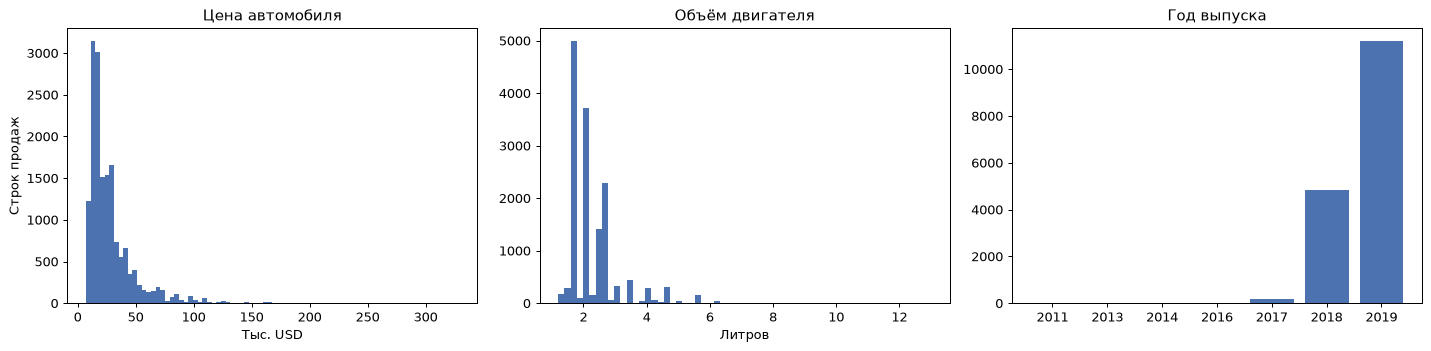

,count,mean,std,min,25%,50%,75%,max
price_usd,16437.0,27921.9,21700.1,7100.0,14615.2,20700.0,32117.2,328511.0
engine_volume,15003.0,2.3,0.9,1.2,1.6,2.0,2.7,13.0
quantity,16437.0,1.8,3.6,-1.0,1.0,1.0,1.0,115.0


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(data['price_usd'] / 1000, bins=80, color='#4C72B0')
axes[0].set_title('Цена автомобиля')
axes[0].set_xlabel('Тыс. USD')
axes[0].set_ylabel('Строк продаж')
axes[1].hist(data['engine_volume'].dropna(), bins=60, color='#4C72B0')
axes[1].set_title('Объём двигателя')
axes[1].set_xlabel('Литров')
years = data['release_year'].value_counts().sort_index()
axes[2].bar(years.index.astype(str), years.values, color='#4C72B0')
axes[2].set_title('Год выпуска')
plt.tight_layout()
plt.show()
data[['price_usd', 'engine_volume', 'quantity']].describe().round(1).T

In [22]:
price_by_segment = data.groupby('segment_2013', observed=True)['price_usd'].describe()
price_by_segment[['count', '25%', '50%', '75%', 'max']].round(0)

,count,25%,50%,75%,max
segment_2013,,,,,
Внедорожники,7865.0,19345.0,27316.0,40584.0,218682.0
Коммерческие автомобили,2210.0,15096.0,18066.0,29738.0,328511.0
Легковые автомобили,5700.0,12700.0,16433.0,22600.0,193600.0
Минивэны,368.0,11300.0,11300.0,13500.0,76143.0
Пикапы,294.0,27398.0,30799.0,35063.0,47399.0


- **Цена**: медиана 20.7 тыс. USD, половина продаж — 14.6–32.1 тыс. USD;
  распределение скошено вправо, хвост до 329 тыс. — автобусы и премиальные
  внедорожники. Самые дешёвые продажи — Lada Granta за 7.1 тыс. USD.
- **Объём двигателя**: типичные значения 1.6, 2.0 и 2.7 л (Lada, Hyundai,
  Toyota и ГАЗ); объёмы 10–13 л — у грузовиков и автобусов.
- **Год выпуска**: 68% строк продаж — автомобили 2019 года, 29% — 2018 года;
  машины 2016 года и старше — единичные остатки склада.
- **Сегменты по цене**: медиана внедорожника — 27.3 тыс. USD, легкового —
  16.4 тыс., минивэна — 11.3 тыс. (Lada Largus).

### 3.2 Продажи по брендам, моделям, регионам, топливу и коробкам передач

,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
brand,,,,,
Lada,11079,107705079.0,9722.0,36.58,15.92
Hyundai,3467,79696274.0,22987.0,11.45,11.78
Toyota,2424,99415851.0,41013.0,8.00,14.69
Kia,2346,45415000.0,19358.0,7.75,6.71
Nissan,1588,38019008.0,23941.0,5.24,5.62
UAZ,1166,16108853.0,13815.0,3.85,2.38
GAZ,1138,20207865.0,17757.0,3.76,2.99
Volkswagen,1022,21077299.0,20624.0,3.37,3.12
Skoda,776,19693150.0,25378.0,2.56,2.91


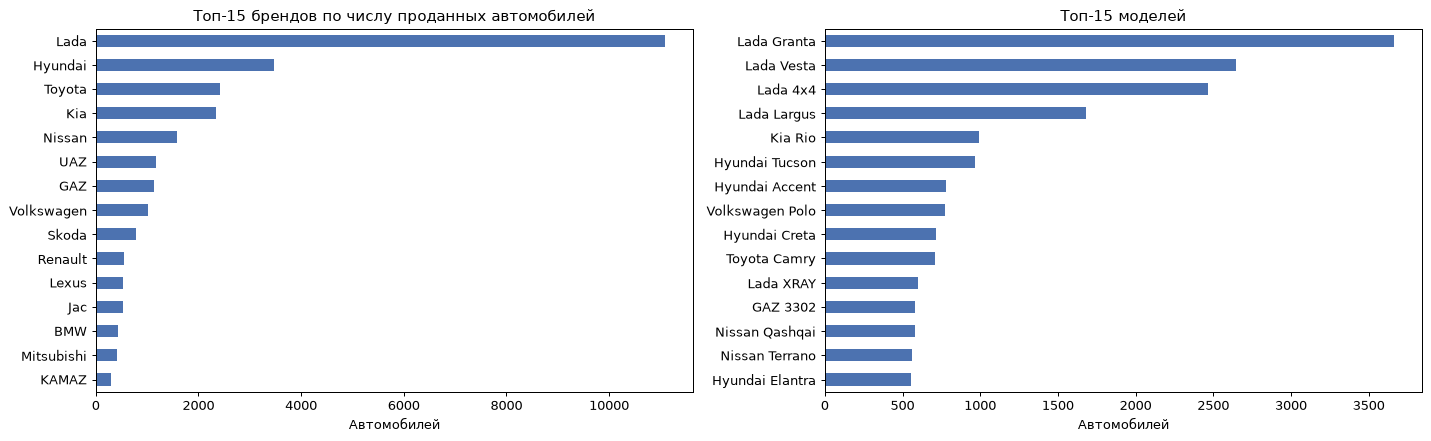

In [23]:
brands = market.sales_summary(data, 'brand')
display(brands.head(15))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
brands['units'].head(15).sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Топ-15 брендов по числу проданных автомобилей')
axes[0].set_xlabel('Автомобилей')
axes[0].set_ylabel('')
models = market.sales_summary(data, ['brand', 'model'])['units'].head(15)
models.index = [f'{brand} {model}' for brand, model in models.index]
models.sort_values().plot(kind='barh', ax=axes[1], color='#4C72B0')
axes[1].set_title('Топ-15 моделей')
axes[1].set_xlabel('Автомобилей')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

In [24]:
regions = market.sales_summary(data, 'region')
regions.head(10)

,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
region,,,,,
Алматы,5840,177676083.0,30424.0,19.28,26.26
Нур-Султан,4387,116272405.0,26504.0,14.49,17.18
Атырау,2332,43777740.0,18773.0,7.70,6.47
Караганда,2092,39728132.0,18991.0,6.91,5.87
Шымкент,1997,39322196.0,19691.0,6.59,5.81
Костанай,1997,40882306.0,20472.0,6.59,6.04
Усть-Каменогорск,1755,32812790.0,18697.0,5.80,4.85
Уральск,1584,30282450.0,19118.0,5.23,4.48
Актобе,1335,29633487.0,22197.0,4.41,4.38


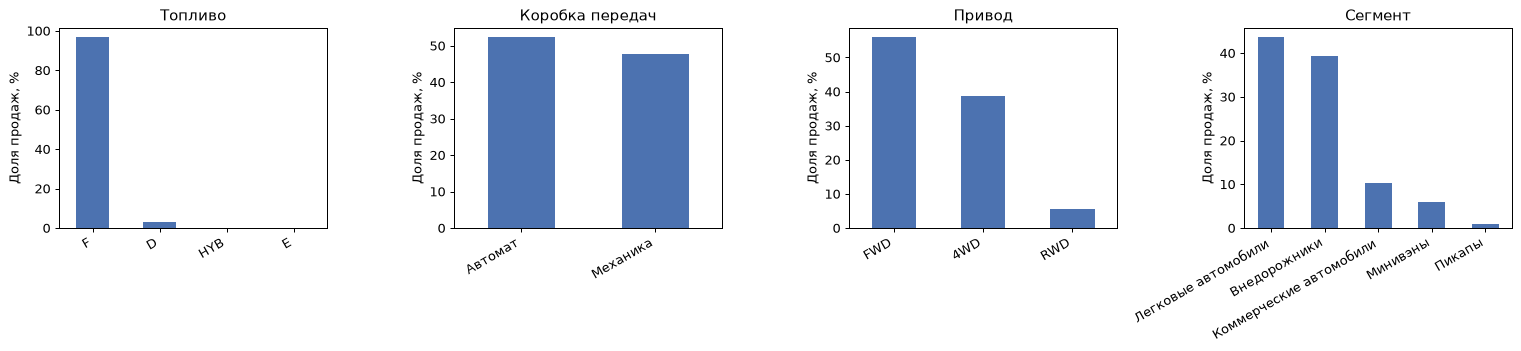

,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
fuel,,,,,
F,28231,590983936.0,20934.0,96.67,91.31
D,959,54922601.0,57271.0,3.28,8.49
HYB,8,540591.0,67574.0,0.03,0.08
E,5,769869.0,153974.0,0.02,0.12


,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
transmission,,,,,
Автомат,14838,437142873.0,29461.0,52.29,69.75
Механика,13539,189624116.0,14006.0,47.71,30.25


,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
drive,,,,,
FWD,15735,228643015.0,14531.0,55.88,37.47
4WD,10880,334468980.0,30742.0,38.64,54.81
RWD,1545,47066776.0,30464.0,5.49,7.71


,units,revenue_usd,avg_check_usd,units_share_pct,revenue_share_pct
segment_2013,,,,,
Легковые автомобили,13200,199799644.0,15136.0,43.59,29.53
Внедорожники,11898,348473839.0,29288.0,39.29,51.50
Коммерческие автомобили,3099,97574545.0,31486.0,10.23,14.42
Минивэны,1790,22010356.0,12296.0,5.91,3.25
Пикапы,296,8741191.0,29531.0,0.98,1.29


In [25]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (column, title) in zip(
    axes,
    [
        ('fuel', 'Топливо'),
        ('transmission', 'Коробка передач'),
        ('drive', 'Привод'),
        ('segment_2013', 'Сегмент'),
    ],
):
    shares = market.sales_summary(data, column)['units_share_pct']
    shares.plot(kind='bar', ax=ax, color='#4C72B0', rot=30)
    plt.setp(ax.get_xticklabels(), ha='right')
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Доля продаж, %')
plt.tight_layout()
plt.show()
for column in ['fuel', 'transmission', 'drive', 'segment_2013']:
    display(market.sales_summary(data, column))

- **Бренды**: рынок сильно сконцентрирован — Lada даёт 36.6% проданных
  автомобилей, вместе с Hyundai, Toyota и Kia — 64%. По выручке Toyota
  уступает только Lada: средний чек Toyota — 41 тыс. USD, Lada — 9.7 тыс.
- **Модели**: лидируют доступные автомобили местной сборки — Lada Granta,
  Vesta, 4x4 и Largus (вместе 34% рынка), Kia Rio, Hyundai Tucson и Accent,
  Volkswagen Polo.
- **Регионы**: Алматы и Нур-Султан дают 34% продаж и 43% выручки — там самый
  высокий средний чек (30.4 и 26.5 тыс. USD). Крупные региональные рынки —
  Атырау, Караганда, Костанай, Шымкент. Регион «Экспорт» — поставки за
  пределы страны, в анализе долей на внутреннем рынке он исключается.
- **Топливо и коробка**: 96.7% автомобилей с бензиновым двигателем, дизель —
  в основном коммерческий транспорт, электромобили и гибриды — единичные.
  Автомат и механика делят рынок почти поровну (52% и 48% штук), но на
  автоматы приходится 70% выручки.
- **Привод и сегменты**: передний привод — 56% продаж, полный — 39%.
  Легковые автомобили — 44% штук, внедорожники — 39% штук, но 51.5% выручки:
  средний чек внедорожника почти вдвое выше легкового.